Enter rotation angle theta in degrees (0-180):  60
Enter number of shots:  1024


State: 0.8660|0> + 0.5000|1>

Measurement counts: {'1': 254, '0': 770}

         Theory   Measured
P(0)     0.7500   0.7520
P(1)     0.2500   0.2480

Expected statistical error: +/- 0.0135


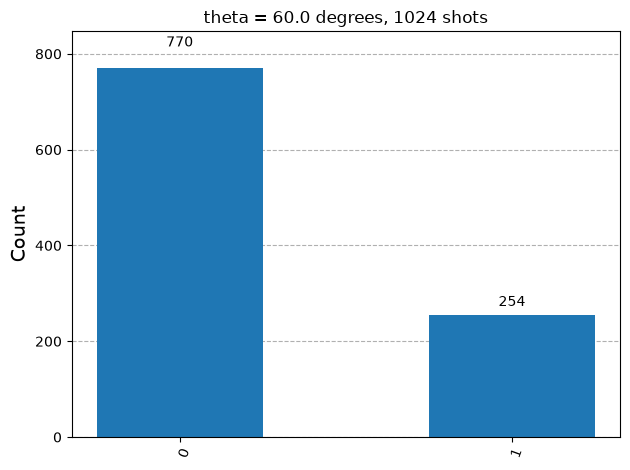

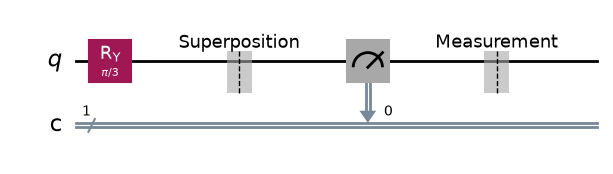

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from IPython.display import display
import numpy as np

# 1. User input
theta_deg = float(input("Enter rotation angle theta in degrees (0-180): "))
shots = int(input("Enter number of shots: "))

if not 0 <= theta_deg <= 180:
    raise ValueError("Theta must be between 0 and 180 degrees.")

if shots <= 0:
    raise ValueError("Shots must be a positive number.")

theta = np.radians(theta_deg)

# 2. Create circuit
q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# 3. Superposition: Ry(theta)|0> = cos(theta/2)|0> + sin(theta/2)|1>
qc.ry(theta, q[0])
qc.barrier(label="Superposition")

# 4. Measurement
qc.measure(q[0], c[0])
qc.barrier(label="Measurement")

# 5. Theoretical probabilities (Born rule)
p0_theory = np.cos(theta / 2)**2
p1_theory = np.sin(theta / 2)**2

print(f"State: {np.cos(theta / 2):.4f}|0> + {np.sin(theta / 2):.4f}|1>")

# 6. Run circuit
result = AerSimulator().run(qc, shots=shots).result()
counts = result.get_counts()

p0_measured = counts.get("0", 0) / shots
p1_measured = counts.get("1", 0) / shots

# 7. Compare theory with measurement
print("\nMeasurement counts:", counts)

print("\n         Theory   Measured")
print(f"P(0)     {p0_theory:.4f}   {p0_measured:.4f}")
print(f"P(1)     {p1_theory:.4f}   {p1_measured:.4f}")

error = np.sqrt(p1_theory * (1 - p1_theory) / shots)
print(f"\nExpected statistical error: +/- {error:.4f}")

display(plot_histogram(counts, title=f"theta = {theta_deg} degrees, {shots} shots"))

# 8. Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_3_Superposition_Measurement.png", dpi=300, bbox_inches="tight")